In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
data=pd.read_csv(r"E:\Downloads\ecg.csv")
data.dropna(inplace=True)
x=data.iloc[:, :-1].values
y=data.iloc[:, -1].values
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
scaler=MinMaxScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.fit_transform(x_test)

C:\Users\biolu\AppData\Local\Temp\ipykernel_35904\218275890.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(inplace=True)


In [4]:
n = x_train.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(n, activation='sigmoid')
])

In [5]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
              loss='mse',
              metrics=['mae'])

In [7]:
history = model.fit(x_train, x_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_test, x_test))

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 320ms/step - loss: 0.0207 - mae: 0.1131 - val_loss: 0.0255 - val_mae: 0.1255
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0113 - mae: 0.0770 - val_loss: 0.0263 - val_mae: 0.1272
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0105 - mae: 0.0726 - val_loss: 0.0251 - val_mae: 0.1244
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0103 - mae: 0.0718 - val_loss: 0.0255 - val_mae: 0.1257
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - loss: 0.0102 - mae: 0.0709 - val_loss: 0.0252 - val_mae: 0.1248
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0100 - mae: 0.0702 - val_loss: 0.0247 - val_mae: 0.1237
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0097 - mae: 0.0696 - val_loss: 0.0233 - val_mae: 0.1207
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.0082 - mae: 0.0636 - val_loss: 0.0202 - val_mae: 0.1123
Epoch 9/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0057 - mae: 0.0517

In [8]:
pred = model.predict(x_test)

error = np.mean((x_test - pred)**2, axis=1)

threshold = np.mean(error) + np.std(error)

y_pred = (error > threshold).astype(int)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step


Accuracy: 0.418


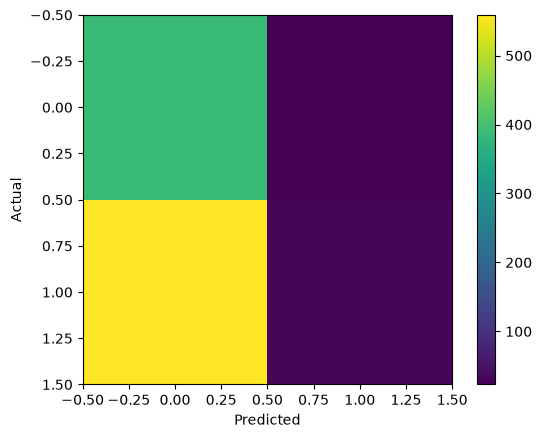

In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm)
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()